The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


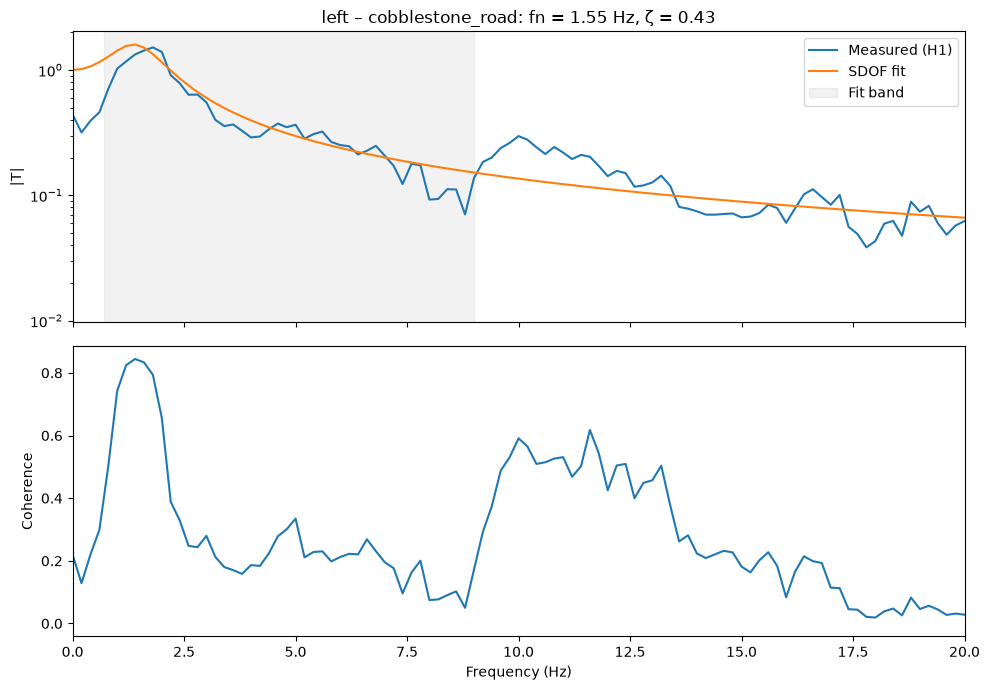

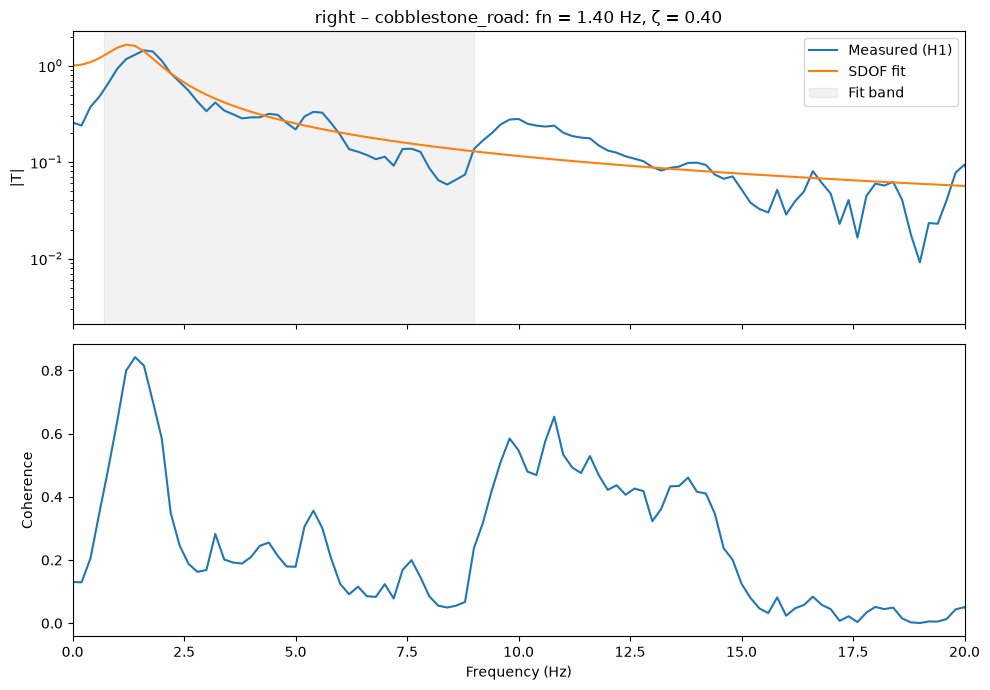

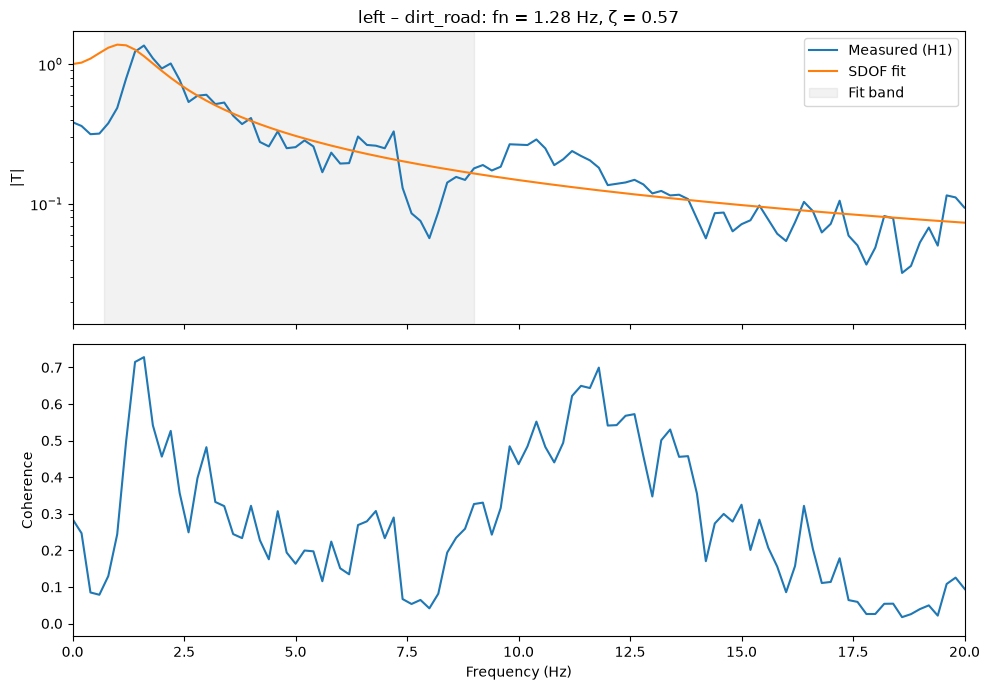

,side,surface,fn_hz,zeta,converged
0,left,cobblestone_road,1.546,0.426,True
1,right,cobblestone_road,1.401,0.401,True
2,left,dirt_road,1.283,0.570,True


In [5]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

from src.spectral import mean_cross_spectral
from src.quarter_car import transmissibility_sdof, fit_sdof
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data={}
for side in ['left', 'right']:
    signals = pd.read_parquet(f'../data/processed/signals_PVS1_{side}.parquet')
    windows = pd.read_csv(f'../data/processed/windows_PVS1_{side}.csv', index_col='window')
    data[side] = (signals, windows)

cases = [('left', 'cobblestone_road'), ('right', 'cobblestone_road'), ('left', 'dirt_road')]

rows = []
for side, surf in cases:
    signals, windows = data[side]
    ids = windows[windows['valid'] & (windows['surface'] == surf)].index
    f, Pxx, Pyy, Pxy = mean_cross_spectral(signals, ids, 'acc_z_below_suspension_filt', 'acc_z_above_suspension_filt')
    H = Pxy / Pxx
    coh = np.abs(Pxy)**2 / (Pxx * Pyy)

    (fn, zeta), result = fit_sdof(f, H, coh, f_min=0.7, f_max=9)
    rows.append({'side': side, 'surface': surf, 'fn_hz': fn, 'zeta': zeta, 'converged': result.success})

    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    axes[0].semilogy(f, np.abs(H), label='Measured (H1)')
    axes[0].semilogy(f, np.abs(transmissibility_sdof(f, fn, zeta)), label='SDOF fit')
    axes[0].axvspan(0.7, 9, color='grey', alpha=0.1, label='Fit band')
    axes[0].set_ylabel('|T|')
    axes[0].set_title(f'{side} – {surf}: fn = {fn:.2f} Hz, ζ = {zeta:.2f}')
    axes[0].legend()
    axes[1].plot(f, coh)
    axes[1].set_ylabel('Coherence')
    axes[1].set_xlabel('Frequency (Hz)')
    axes[1].set_xlim(0, 20)
    plt.tight_layout()
    fig.savefig(f'../figures/p7_sdof_fit_{side}_{surf}.png', dpi=150, bbox_inches='tight')
    plt.show()

fits = pd.DataFrame(rows)
display(fits.round(3))

## Part 7 – Conclusions (PVS 1)

1. **Model:** with the wheel acceleration (below the suspension) as input, the path to the body is a base-excited single-degree-of-freedom system. Only the natural frequency (fn = sqrt(k/M)) and damping ratio (zeta) can be identified from these data; spring rate, damping coefficient and sprung mass cannot be separated without knowing the mass. The wheel-hop mode does not appear in this model, since the wheel is the input.
2. **Fitted parameters** (cases with high coherence at the body mode): fn = 1.55 Hz and zeta = 0.43 (cobblestone, left), fn = 1.40 Hz and zeta = 0.40 (cobblestone, right), fn = 1.28 Hz and zeta = 0.57 (dirt, left). All fits converged within the parameter bounds.
3. **Fit quality:** the model reproduces the measured transmissibility in the fit band (0.7–9 Hz), including the body-mode peak and the isolation region. Below ~1 Hz the measured |T| drops due to low coherence (weak excitation after the 0.5 Hz high-pass filter), not to the model.
4. **Comparison with Part 4:** the full-curve fit gives zeta = 0.40–0.57, consistent with the peak-height estimate (0.44–0.54) and above the half-power bandwidth estimate (0.22–0.31), whose low-damping assumption is not met.
5. **Variability between cases:** since the suspension is the same, fn and zeta should not depend on the surface. Left and right on cobblestone agree closely (1.40–1.55 Hz, zeta 0.40–0.43). The differences between cases are attributed mainly to estimation uncertainty (0.2 Hz frequency resolution, coherence, number of windows); amplitude-dependent (non-linear) damper behaviour is a possible contributing factor that cannot be confirmed with three cases.
6. **Unmodelled behaviour:** the model does not reproduce the local transmissibility maximum at ~10–12 Hz (coherence 0.5–0.6), confirming that the transmission path includes additional compliance or dynamics (e.g. bushings, strut top mount or a local body mode).
7. **Future work:** obtain the sprung mass (vehicle specifications or corner weights) to convert fn and zeta into effective wheel rate and damping; extend the model with a series compliance to explain the 10–12 Hz maximum; and use a two-degree-of-freedom quarter-car model with a road-profile input to study the trade-off between ride comfort and tyre contact force.